# Experiment 000: Image representation

## Objective

Understand how digital images are represented numerically in Python before using them as inouts to a nerural network.

## Questions
- How is an image represented in memory?
- What does each image dimension represent?
- What numerical values are stored in individual pixels?
- How are red, green, and blue channels separated?

In [6]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [7]:
data_dir = Path("../data/raw/shipsnet")

image_path = next(data_dir.glob("*.png"))

print(image_path)

..\data\raw\shipsnet\0__20150718_184300_090b__-122.35324421973536_37.772113980272394.png


<PIL.PngImagePlugin.PngImageFile image mode=RGB size=80x80 at 0x21BA8A62510>
Size: (80, 80)
Mode: RGB


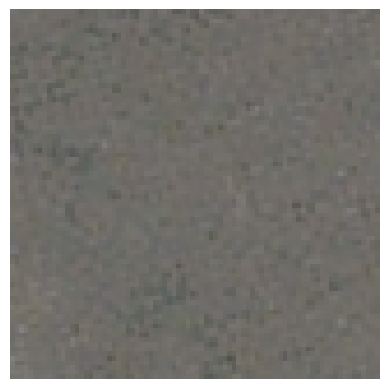

In [8]:
image = Image.open(image_path)

print(image)
print("Size:", image.size)
print("Mode:", image.mode)

plt.imshow(image)
plt.axis("off")
plt.show()

In [9]:
image_array = np.array(image)

print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)

pixel = image_array[0, 0]
print("Top-left pixel:", pixel)

Array shape: (80, 80, 3)
Data type: uint8
Top-left pixel: [116 114 109]


In [10]:
red_channel = image_array[:, :, 0]
green_channel = image_array[:, :, 1]
blue_channel = image_array[:, :, 2]

print("Red shape", red_channel.shape)
print("Green shape", green_channel.shape)
print("Blue shape", blue_channel.shape)



Red shape (80, 80)
Green shape (80, 80)
Blue shape (80, 80)


[[116 114 109 109 111]
 [111 111 111 111 114]
 [110 113 115 115 114]
 [110 110 112 115 110]
 [109 107 110 113 111]]


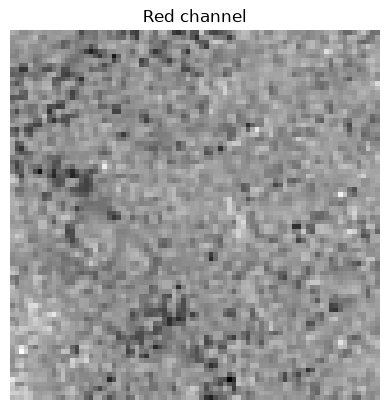

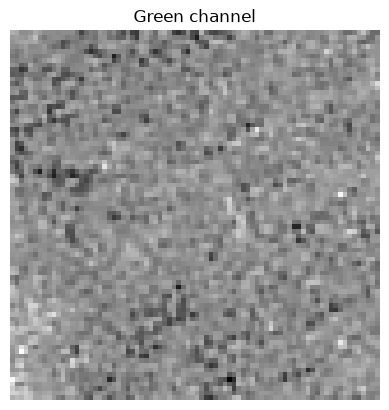

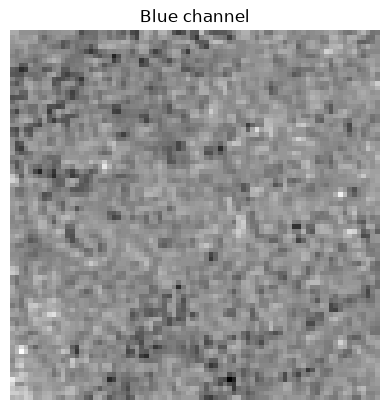

In [11]:
print(red_channel[:5, :5])
plt.imshow(red_channel, cmap="gray")
plt.title("Red channel")
plt.axis("off")
plt.show()

plt.imshow(green_channel, cmap="gray")
plt.title("Green channel")
plt.axis("off")
plt.show()

plt.imshow(blue_channel, cmap="gray")
plt.title("Blue channel")
plt.axis("off")
plt.show()

## Inturpretation 

A ShipsNet image is represented as an 80x80x3 numerical array.
The first two dimensions identity the locaion of a pixel in the image, while the third dimension contains its RGB intensity values.
Each RGB channel cna be represented independently as an 80x80 matrix. Togetherm the three matrices contain 19,200 numerical values that completely describe the image.

In [12]:
row = 10
col = 10

print("Red:", red_channel[row, col])
print("Green:", green_channel[row, col])
print("Blue:", blue_channel[row, col])
print("Original RGB pixel:", image_array[row, col])
print("Number of values:", image_array.size)

Red: 97
Green: 95
Blue: 90
Original RGB pixel: [97 95 90]
Number of values: 19200


In [13]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

PyTorch version: 2.13.0+cu130
CUDA available: True
GPU NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [14]:
image_tensor = torch.from_numpy(image_array)

print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)

Tensor shape: torch.Size([80, 80, 3])
Tensor dtype: torch.uint8


In [15]:
image_tensor = image_tensor.permute(2, 0, 1)

print("Reorderd tensor shape:", image_tensor.shape)



Reorderd tensor shape: torch.Size([3, 80, 80])


In [16]:
print("dtype:", image_tensor.dtype)
print("min:", image_tensor.min())
print("max:", image_tensor.max())

dtype: torch.uint8
min: tensor(75, dtype=torch.uint8)
max: tensor(133, dtype=torch.uint8)


In [17]:
image_tensor = image_tensor.float()
print("dtype:", image_tensor.dtype)

image_tensor = image_tensor / 255.0

print("min:", image_tensor.min())
print("max:", image_tensor.max())
print(image_tensor.shape)

dtype: torch.float32
min: tensor(0.2941)
max: tensor(0.5216)
torch.Size([3, 80, 80])


In [18]:
batched_image = image_tensor.unsqueeze(0)
print(batched_image.shape)

torch.Size([1, 3, 80, 80])


In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [20]:
batched_image = batched_image.to(device)
print(batched_image.device)

cuda:0


In [21]:
import torch.nn as nn

In [22]:
conv = nn.Conv2d(
    in_channels=3,
    out_channels=8,
    kernel_size=3,
    padding=1
)
conv = conv.to(device)

print(conv)
print("Weight shape:", conv.weight.shape)
print("Bias shape:", conv.bias.shape)


Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
Weight shape: torch.Size([8, 3, 3, 3])
Bias shape: torch.Size([8])


In [23]:
feature_maps = conv(batched_image)
print("Input shape:", batched_image.shape)
print("Output shape:", feature_maps.shape)

Input shape: torch.Size([1, 3, 80, 80])
Output shape: torch.Size([1, 8, 80, 80])


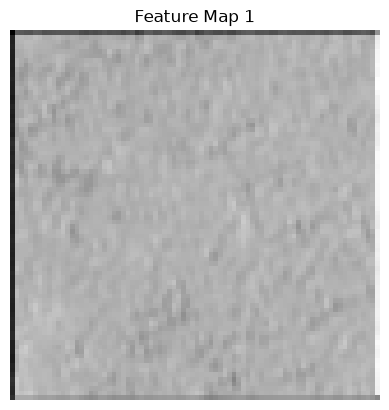

In [24]:
first_feature_map = feature_maps[0, 0].detach().cpu().numpy()

plt.imshow(first_feature_map, cmap="grey")
plt.title("Feature Map 1")
plt.axis("off")
plt.show()

In [25]:
row = 10
col = 10

patch = batched_image[
    0,
    :,
    row - 1:row + 2,
    col - 1:col + 2
]
print("Patch shape:", patch.shape)
print(patch)

Patch shape: torch.Size([3, 3, 3])
tensor([[[0.4549, 0.4196, 0.3725],
         [0.3922, 0.3804, 0.3843],
         [0.3922, 0.4000, 0.4392]],

        [[0.4392, 0.4157, 0.3804],
         [0.3804, 0.3725, 0.3843],
         [0.3804, 0.3922, 0.4314]],

        [[0.4235, 0.3961, 0.3569],
         [0.3647, 0.3529, 0.3569],
         [0.3608, 0.3686, 0.4039]]], device='cuda:0')


In [26]:
filter_weights = conv.weight[0]
filter_bias = conv.bias[0]
print("Filter shape:", filter_weights.shape)
print("Bias:", filter_bias)

Filter shape: torch.Size([3, 3, 3])
Bias: tensor(0.1106, device='cuda:0', grad_fn=<SelectBackward0>)


In [27]:
manual_value = (patch * filter_weights).sum() + filter_bias

print("Manual calculation:", manual_value)

Manual calculation: tensor(0.5087, device='cuda:0', grad_fn=<AddBackward0>)


In [28]:
pytorch_value = feature_maps[0, 0, row, col]

print("PyTorch Conv2d:", pytorch_value)
print("Manual result:", manual_value)
print(torch.allclose(manual_value, pytorch_value))

PyTorch Conv2d: tensor(0.5087, device='cuda:0', grad_fn=<SelectBackward0>)
Manual result: tensor(0.5087, device='cuda:0', grad_fn=<AddBackward0>)
True


In [29]:
relu = nn.ReLU()
activated_maps = relu(feature_maps)

print("Before ReLU")
print(f"Min: {feature_maps.min().item()}")
print(f"Max: {feature_maps.max().item()}")

print(f"After ReLU")
print(f"Min: {activated_maps.min().item()}")
print(f"Max: {activated_maps.max().item()}")

Before ReLU
Min: -0.4300263226032257
Max: 0.7115355134010315
After ReLU
Min: 0.0
Max: 0.7115355134010315


In [30]:
negative_before = (feature_maps < 0).sum()
negative_after = (activated_maps < 0).sum()

print(f"Negative values before ReLU: {negative_before.item()}")
print(f"Negative values after ReLU {negative_after.item()}")

Negative values before ReLU: 25685
Negative values after ReLU 0


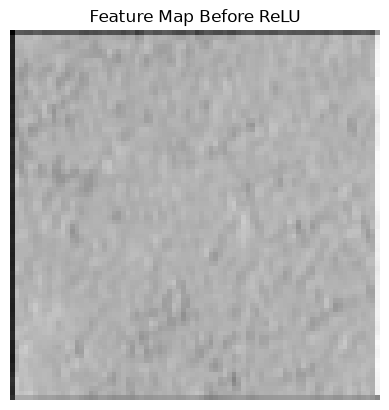

<function matplotlib.pyplot.show(close=None, block=None)>

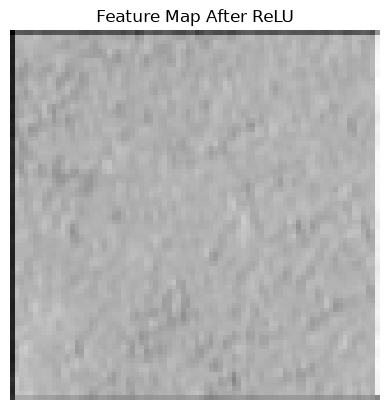

In [31]:
before_relu = feature_maps[0,0].detach().cpu().numpy()
after_relu = activated_maps[0,0].detach().cpu().numpy()

plt.imshow(before_relu, cmap="grey")
plt.title("Feature Map Before ReLU")
plt.axis("off")
plt.show()

plt.imshow(after_relu, cmap="grey")
plt.title("Feature Map After ReLU")
plt.axis("off")
plt.show

In [32]:
pool = nn.MaxPool2d(kernel_size=2, stride=2)

pooled_maps = pool(activated_maps)

print(f"Before pooling: {activated_maps.shape}")
print(f"After pooling: {pooled_maps.shape}")

Before pooling: torch.Size([1, 8, 80, 80])
After pooling: torch.Size([1, 8, 40, 40])


In [35]:
region = activated_maps[0, 0, 0:2, 0:2]

print("2x2 region:")
print(region)

print(f"\nMaximum value: {region.max().item()}")
print(f"Pooling output: {pooled_maps[0, 0, 0, 0].item()}")

2x2 region:
tensor([[0.1770, 0.3684],
        [0.2486, 0.5560]], device='cuda:0', grad_fn=<SliceBackward0>)

Maximum value: 0.5560091137886047
Pooling output: 0.5560091137886047
